# The capital plan: pre-provision net revenue, the CET1 path, the EBA static balance sheet and the Chilean capital stack

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 04 of this topic (the scenarios and the loss rates they imply)
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- build the three-year CET1 path of a stress scenario from the starting capital and the losses of notebook 04, with and without a labelled pre-provision net revenue (PPNR) row, and say why the headline is the loss-only path;
- compute the Chilean internal capital target (the OI), its components and the 4 percent cap that binds the article 66 quinquies requirement and not the bank's own estimate, and the legal minimum that the plan is tested against;
- run the three cases of the plan (base, stress without mitigation, stress with mitigation) with `capital_plan`, and read why the stressed bank can hold the legal minimum and still miss its own internal target;
- apply the EBA 2025 static balance-sheet rules to the stage balances and have the engine's test catch a cure and a change of the total;
- compute the Contraste approximation of the Pillar 2 guidance, and rebuild the 34 rows of the CMF Annex 3 summary form, comparing every row with the committed ones.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. The engine's own texts (test identifiers, messages, notes and docstrings) are printed as the engine writes them, in English, in both trees.

This notebook also reads one constants file of the product's pipeline, `data-pipeline/pipeline/cases/c18/params.py` (the map from the six C07 segments to the three loan classes). The pipeline is a set of scripts and not a package, so the notebook loads that one file by its path with the standard library: one source for the map, never a copy. The file has no dependency.

The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Import the engine and the helpers, and print the versions of the packages this notebook uses
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import importlib.util

import matplotlib.pyplot as plt
from riskvalidation.stress import capital
from riskvalidation.validation import stress as stress_tests
for name in ("riskvalidation", "numpy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Data

This notebook reads the capital side of **C18** (Banco Andino).

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 0.8.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` and `fed-2026-severely-adverse.json` (`outputs.capital_start`, `losses`, `internal_capital_target`, `headline_cet1`, `capital_plan`, `p2g_proxy`, `annex3`), the models document `models-banco-andino.json` (the Chilean stack, the EBA rules by paragraph), `reverse-stress.json` (the failure-point stack), and, for the static balance sheet, the stage balances and the segment parameters of the provisions case C07 (`data/derived/C07/base.json` and `models-banco-andino.json`) and the segment-to-class map of `data-pipeline/pipeline/cases/c18/params.py`.
- **Banco Andino's capital is an anchor, not a balance sheet.** CET1 is the Tier 1 proxy of the interest-rate case C15; the risk-weighted assets (RWA) are that proxy over the 11.0 percent CET1 anchor, split between credit, market and operational risk by the mix of a large Chilean bank's 2025 Form 20-F (ratios only, because the filing is derived-only). The part of the effective equity above CET1 is carried as Tier 2 and AT1 is nil, an assumption **UNVERIFIED** in the sources and labelled so in the document. Money is in CLP millions and shares are shares of RWA.

In [2]:
# The notebook sits three folders below the repository root; a missing file stops the notebook and names its path
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


print("derived folder found:", DERIVED.is_dir())

baseline = read_json("C18/baseline.json")["outputs"]
fed_doc = read_json("C18/fed-2026-severely-adverse.json")
fed = fed_doc["outputs"]
models = read_json("C18/models-banco-andino.json")["fit"]
start = fed["capital_start"]
print("baked by riskvalidation", fed_doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("jump-off:", fed["bank"]["as_of"], "| RWA:", round(start["rwa_clp_m"], 1), "| CET1:", round(start["cet1_clp_m"], 1), "| CET1 ratio:", start["cet1_ratio"], "| PE ratio:", round(start["pe_ratio"], 6))
print("RWA by risk:", {k: round(v, 0) for k, v in start["rwa_by_risk"].items()}, "| AT1:", start["at1_clp_m"], "| T2:", round(start["t2_clp_m"], 1))

derived folder found: True
baked by riskvalidation 0.8.1 | installed 0.8.1
jump-off: 2026-08-31 | RWA: 7492853.0 | CET1: 824213.8 | CET1 ratio: 0.11 | PE ratio: 0.168938
RWA by risk: {'credit': 5307997.0, 'market': 1283189.0, 'operational': 901667.0} | AT1: 0.0 | T2: 441613.8


## Method

### Step 1: the headline path, CET1 less the losses

The **headline** CET1 path of the case is the **loss-only depletion**: CET1 at the jump-off less the cumulated stressed losses of the years so far, with no revenue invented,

$$\mathrm{CET1}_y = \mathrm{CET1}_0 - \sum_{s \le y} L_s, \qquad y = 1, 2, 3.$$

The loss of a year is the sum of the credit loss of notebook 04 and the expected losses of the other risks: market and operational risk have no position book or macro map in the case, so each carries its annual expected loss in every scenario and the stressed loss is a floor. The IRRBB loss is nil because an economic-value change is not a profit-and-loss item of the banking book; the rate path acts on net interest income instead (step 2). `cet1_path_loss_only(cet1_0, losses)` computes the path. The next cell reads the losses of the severely adverse scenario, builds the path and compares with the committed headline rows.

In [3]:
# The loss-only CET1 path of the severely adverse scenario against the committed headline rows
loss_rows = fed["losses"]["scenario_losses"]
losses = [row["total"] for row in loss_rows]
for row in loss_rows:
    print(f'year {row["year"]}: credit {row["credit"]:10,.0f} + market {row["market"]:.0f} + IRRBB {row["irrbb"]:.0f} + operational {row["operational"]:8,.0f} = total {row["total"]:10,.0f}')
path = capital.cet1_path_loss_only(start["cet1_clp_m"], losses)
committed_rows = fed["headline_cet1"]["rows"]
print("CET1 path (engine):", np.round(path, 1))
print("committed          :", np.round([row["cet1_clp_m"] for row in committed_rows], 1))
print("CET1 ratio by year :", np.round(path / start["rwa_clp_m"], 4), "| method:", fed["headline_cet1"]["method"])

year 1: credit     86,519 + market 0 + IRRBB 0 + operational    1,188 = total     87,706
year 2: credit    111,987 + market 0 + IRRBB 0 + operational    1,188 = total    113,174
year 3: credit     71,005 + market 0 + IRRBB 0 + operational    1,188 = total     72,193
CET1 path (engine): [736507.7 623333.4 551140.8]
committed          : [736507.7 623333.4 551140.8]
CET1 ratio by year : [0.0983 0.0832 0.0736] | method: loss-only-depletion


### Step 2: the labelled PPNR row

A bank earns while it loses. The case adds a **labelled row** with pre-provision net revenue, never the headline. The net interest income (NII) of each year follows the scenario's rate path through the interest-rate engine of topic 09 on the C15 book; the fee income and the operating cost are two stated constant ratios, assumptions of the case and not Banco Andino or CMF figures:

$$\text{fees} = r_{\text{fee}}\cdot\mathrm{NII},\qquad \text{cost} = r_{\text{cost}}\,(\mathrm{NII} + \text{fees}),\qquad \mathrm{PPNR} = \mathrm{NII} + \text{fees} - \text{cost},$$

with $r_{\text{fee}} = 0.25$ and $r_{\text{cost}} = 0.55$. The Federal Reserve documents no PPNR model in the dossiers; its efficiency-ratio element is only the precedent for a cost ratio. `ppnr_row(nii, fee_ratio, cost_ratio)` computes the row. The next cell recomputes the three years of the severely adverse scenario from the committed NII, prints each step, and compares with the committed rows, including the CET1 with PPNR.

In [4]:
# Recompute the PPNR row of each year from the committed NII and the two stated ratios, and the CET1 with PPNR
ppnr = fed["headline_cet1"]["ppnr"]
fee_ratio, cost_ratio = ppnr["fee_ratio"]["value"], ppnr["cost_ratio"]["value"]
print("fee ratio:", fee_ratio, "| cost ratio:", cost_ratio, "| labels:", ppnr["fee_ratio"]["label"], "and", ppnr["cost_ratio"]["label"])
cumulative = 0.0
for k, row in enumerate(ppnr["rows"]):
    mine = capital.ppnr_row(row["nii_clp_m"], fee_ratio, cost_ratio)
    cumulative += mine.ppnr
    cet1_with = path[k] + cumulative
    print(f'year {row["year"]}: NII {mine.nii:9,.0f} + fees {mine.fee_income:8,.0f} - cost {mine.operating_cost:9,.0f} = PPNR {mine.ppnr:9,.0f} | CET1 with PPNR {cet1_with:10,.0f} (committed {row["cet1_with_ppnr_clp_m"]:10,.0f}) | ratio {cet1_with / start["rwa_clp_m"]:.4f}')

fee ratio: 0.25 | cost ratio: 0.55 | labels: case assumption and case assumption
year 1: NII   262,778 + fees   65,695 - cost   180,660 = PPNR   147,813 | CET1 with PPNR    884,320 (committed    884,320) | ratio 0.1180
year 2: NII   261,458 + fees   65,364 - cost   179,752 = PPNR   147,070 | CET1 with PPNR    918,216 (committed    918,216) | ratio 0.1225
year 3: NII   261,458 + fees   65,364 - cost   179,752 = PPNR   147,070 | CET1 with PPNR    993,093 (committed    993,093) | ratio 0.1325


### Step 3: the internal capital target and the legal minimum

Under Chile's IAPE framework (CMF RAN 21-13, Chapter 21-13 section I; dossier 03) a bank sets an **internal target** for effective equity over RWA,

$$\mathrm{OI} \;\ge\; 8\% + c_{\mathrm{DSIB}} + c_{P2} + c_{\mathrm{CCoB}} + c_{\mathrm{CCyB}} + c_d,$$

the 8 percent minimum plus the systemic-bank buffer, the bank's own Pillar 2 estimate, the conservation and countercyclical buffers and a voluntary stress buffer $c_d$ (which may be zero). The Pillar 2 term has two distinct things in it: the **article 66 quinquies requirement** $p2r$, which the CMF sets and which the law caps at **4 percent of RWA**, and the bank's own estimate $c_{P2} \ge p2r$, which has no cap. The engine's `internal_capital_target` enforces both facts. The legal minimum against which the stress is tested is $8\% + c_{\mathrm{DSIB}} + p2r$.

The next cell builds the target with the committed components, prints each one, and shows the engine refusing a requirement above the cap and an own estimate below the requirement. It then computes `chilean_cet1_stack`, the minimum CET1 over RWA of the legal stack ($4.5\% + 2.5\% + \text{CCyB} + c_{\mathrm{DSIB}} + $ the CET1 share of Pillar 2), with the share that the reverse stress of notebook 06 uses.

In [5]:
# Build the internal target and the legal minimum from the committed components; show the two refusals; compute the CET1 stack
target = fed["internal_capital_target"]
stack = models["bank_anchors"]["chilean_stack"]
oi = capital.internal_capital_target(target["c_dsib"], target["c_p2"]["value"], target["c_ccob"], target["c_ccyb"], target["c_d"]["value"], p2r=stack["p2r"])
print("components:", {"min_pe": oi.min_pe, "c_dsib": oi.c_dsib, "c_p2 (own estimate)": oi.c_p2, "c_ccob": oi.c_ccob, "c_ccyb": oi.c_ccyb, "c_d": oi.c_d, "p2r (art. 66 quinquies)": oi.p2r})
print("OI:", round(oi.oi, 6), "| committed:", round(target["oi"], 6), "| labels of c_p2 and c_d:", target["c_p2"]["label"], "and", target["c_d"]["label"])
legal_minimum = oi.min_pe + oi.c_dsib + oi.p2r
print("legal minimum (8% + c_DSIB + p2r):", round(legal_minimum, 6), "| committed requirement of the stress cases:", fed["capital_plan"]["cases"][1]["years"][0]["requirement"]["pct_of_rwa"])
for why, kwargs in (("p2r above the 4 percent cap", dict(p2r=0.05, c_p2=0.05)), ("own estimate below p2r", dict(p2r=0.02, c_p2=0.01))):
    try:
        capital.internal_capital_target(target["c_dsib"], kwargs["c_p2"], target["c_ccob"], target["c_ccyb"], target["c_d"]["value"], p2r=kwargs["p2r"])
    except ValueError as err:
        print(f"{why}: refused: {err}")
reverse = read_json("C18/reverse-stress.json")["outputs"]["failure_point"]["stack"]
print("CET1 stack with the reverse stress share:", round(capital.chilean_cet1_stack(reverse["c_ccyb"], reverse["c_dsib"], reverse["p2_cet1"]["value"]), 6), "| committed:", reverse["total"])

components: {'min_pe': 0.08, 'c_dsib': 0.015, 'c_p2 (own estimate)': 0.01, 'c_ccob': 0.025, 'c_ccyb': 0.005, 'c_d': 0.01, 'p2r (art. 66 quinquies)': 0.00125}
OI: 0.145 | committed: 0.145 | labels of c_p2 and c_d: case assumption and case assumption
legal minimum (8% + c_DSIB + p2r): 0.09625 | committed requirement of the stress cases: 0.09625
p2r above the 4 percent cap: refused: p2r = 0.05 is above the 0.04 cap of RWA on the art. 66 quinquies requirement (03 l.253)
own estimate below p2r: refused: c_p2 = 0.01 is below p2r = 0.02: the bank's estimate includes the art. 66 quinquies requirement
CET1 stack with the reverse stress share: 0.090625 | committed: 0.09062500000000001


### Step 4: the three cases of the plan

`capital_plan(rwa, cet1_0, at1, t2, base_cet1, stress_losses, mitigation_effects, oi, legal_minimum)` returns, for three years, the three cases of the IAPE projection (dossier 03):

- **base:** CET1 from the caller's baseline path (the baseline scenario's CET1 with its PPNR), tested against the internal target OI;
- **stress without mitigation:** the loss-only path of step 1, tested against the legal minimum;
- **stress with mitigation:** the same path plus the cumulated mitigation actions.

Under the **static balance sheet** of the EBA rules the RWA is the same every year, AT1 and Tier 2 stay at their jump-off values, and no capital measure is allowed after the reference date. The sources name no mitigation action, so the case assumes none (the mitigation case equals the unmitigated one and row 10.2 of Annex 3 is not applicable). The headroom of a year is the effective-equity ratio less the requirement, and the deficit is $\max(0, \text{requirement}\cdot\mathrm{RWA} - \mathrm{PE})$.

The base path is the baseline scenario's CET1 with PPNR, which the next cell rebuilds from the baseline document's own losses and PPNR rows before calling the engine. It prints each case by year, compares with the committed plan, and then prints the one comparison the plan does not make by itself: the stressed effective equity against the **internal target**, not only the legal minimum.

In [6]:
# Rebuild the base CET1 path (baseline losses and PPNR), run the three cases, compare with the committed plan, and test against the OI
base_rows = baseline["headline_cet1"]["ppnr"]["rows"]
base_losses = [row["total"] for row in baseline["losses"]["scenario_losses"]]
base_cet1 = start["cet1_clp_m"] + np.cumsum([r["ppnr_clp_m"] - loss for r, loss in zip(base_rows, base_losses)])
plan = capital.capital_plan(start["rwa_clp_m"], start["cet1_clp_m"], start["at1_clp_m"], start["t2_clp_m"], base_cet1, losses, [0.0, 0.0, 0.0], oi.oi, legal_minimum)
committed_cases = {c["case"]: c["years"] for c in fed["capital_plan"]["cases"]}
for case, years in plan.items():
    gap = max(abs(y.headroom_pct - c["headroom_pct_of_rwa"]) for y, c in zip(years, committed_cases[case]))
    print(f"{case:26s} requirement {years[0].requirement_pct:.5f} | PE ratio by year {[round(y.pe_pct, 4) for y in years]} | headroom {[round(y.headroom_pct, 4) for y in years]} | deficit {[round(y.deficit) for y in years]} | gap to committed {gap:.0e}")
print("stress without mitigation, PE ratio less the internal target OI:", [round(y.pe_pct - oi.oi, 4) for y in plan["stress-without-mitigation"]])
print("committed smallest headroom over the OI in the stress:", round(fed["capital_plan"]["cases"][1]["years"][2]["pe"]["pct_of_rwa"] - target["oi"], 4))

base                       requirement 0.14500 | PE ratio by year [0.1837, 0.1981, 0.212] | headroom [0.0387, 0.0531, 0.067] | deficit [0, 0, 0] | gap to committed 3e-17
stress-without-mitigation  requirement 0.09625 | PE ratio by year [0.1572, 0.1421, 0.1325] | headroom [0.061, 0.0459, 0.0362] | deficit [0, 0, 0] | gap to committed 0e+00
stress-with-mitigation     requirement 0.09625 | PE ratio by year [0.1572, 0.1421, 0.1325] | headroom [0.061, 0.0459, 0.0362] | deficit [0, 0, 0] | gap to committed 0e+00
stress without mitigation, PE ratio less the internal target OI: [0.0122, -0.0029, -0.0125]
committed smallest headroom over the OI in the stress: -0.0125


The legal minimum is held in every year of the severely adverse scenario, with headroom that narrows from 6.1 to 3.6 points of RWA, and the deficit is nil. The internal target is another matter: the effective-equity ratio is above the OI in the first year and below it in the second and third. **Holding the legal minimum and missing the bank's own target are two different findings**, and the plan reports both: the first is a question of solvency under the regulation, the second of whether the bank's own risk appetite survives the scenario.

### Step 5: the EBA static balance-sheet rules

The EBA 2025 methodological note (paragraphs 33, 34 and 90 to 92) fixes the balance sheet during the stress: the total exposure is constant, maturing exposures are replaced by similar ones, **new stage 3 exposures move into the stock of stage 3 and nothing leaves it** (no cures, charge-offs or write-offs within the three years), and impairments are computed on a constant balance sheet. `eba_static_balance_sheet(stage_balances, new_s3_flows)` applies the stage 3 rule: each period's new stage 3 exposure leaves stages 1 and 2 pro rata to their balances and joins stage 3. The next cell prints the committed rules by paragraph (the statements are quotations of the EBA text, in English), builds the 12 quarterly flows from the satellite rates (the quarterly charge-off amount over the loss given default of the class, the exposure that defaulted), runs the rule from the stage balances of the provisions case C07, and calls the engine's `static_balance_sheet_rules` test. The segment-to-class map is the one of `params.py`.

In [7]:
# Load the segment-to-class map from the pipeline file, build the quarterly new-stage-3 flows, apply the rule and test it
for rule in models["capital_engine"]["rules"]:
    print(f'paragraph {rule["paragraph"]:>3s}: {rule["statement"][:100]}')
spec = importlib.util.spec_from_file_location("c18_params", ROOT / "data-pipeline" / "pipeline" / "cases" / "c18" / "params.py")
c18_params = importlib.util.module_from_spec(spec)
spec.loader.exec_module(c18_params)
c07 = read_json("C07/base.json")["outputs"]
c07_fit = {s["segment_id"]: s for s in read_json("C07/models-banco-andino.json")["fit"]["ifrs9"]["segments"]}
exposure, lgd_weighted = {}, {}
for segment in c07["portfolio"]["segments"]:
    klass, amount = c18_params.SEGMENT_CLASS[segment["segment_id"]], segment["gross_exposure"] / 1e6
    exposure[klass] = exposure.get(klass, 0.0) + amount
    lgd_weighted[klass] = lgd_weighted.get(klass, 0.0) + amount * c07_fit[segment["segment_id"]]["lgd"]
class_lgd = {k: lgd_weighted[k] / exposure[k] for k in exposure}
class_rates = {k["banco_andino_class"]: np.array([q["rate"] for q in k["quarters"]]) for k in fed["satellites"]["banco_andino_classes"]}
flows = np.array([sum(exposure[k] * max(class_rates[k][q], 0.0) / 4.0 / class_lgd[k] for k in exposure) for q in range(12)])
stage_balances = np.array([row["gross_carrying_amount"] / 1e6 for row in c07["ifrs9_detail"]["stage_summary"]][:3])
print("stage balances 1, 2, 3 at the jump-off:", np.round(stage_balances, 0), "| class LGD:", {k: round(v, 3) for k, v in class_lgd.items()})
print("new stage 3 exposure, first 4 quarters:", np.round(flows[:4], 0), "| total over 12 quarters:", round(float(flows.sum()), 0))
balances = capital.eba_static_balance_sheet(stage_balances, flows)
print("after quarter 1 :", np.round(balances[0], 0), "| after quarter 12:", np.round(balances[-1], 0), "| total constant:", bool(np.allclose(balances.sum(axis=1), stage_balances.sum())))
tolerance = 1e-9 * float(stage_balances.sum())
result = stress_tests.static_balance_sheet_rules(balances, tolerance=tolerance)
committed_test = next(t for t in fed_doc["tests"] if t["test_id"] == "stress.static_balance_sheet_rules")
print("engine test:", result.light.value, "| violated:", result.extras["violated"], "| n:", result.n, "| committed:", committed_test["light"], committed_test["extras"]["violated"], committed_test["n"])

paragraph  24: The exercise is carried out on the basis of year-end 2024 figures, and the scenarios will be applied
paragraph  33: Static balance sheet: assets and liabilities that mature or amortise within the horizon are replaced
paragraph  34: The same business mix and model throughout the horizon; revenues and costs under zero growth and a s
paragraph  90: Banks are not permitted to replace S3 exposures; new S3 exposures move into the stock of S3, keeping
paragraph  91: The initial residual maturity is kept constant for credit REA.
paragraph  92: A constant balance sheet for impairments: replacement assets keep the credit risk characteristics an
stage balances 1, 2, 3 at the jump-off: [5420854.  437917.  141229.] | class LGD: {'mortgage': 0.112, 'consumer': 0.694, 'commercial': 0.24}
new stage 3 exposure, first 4 quarters: [ 50861.  79665. 101175. 116751.] | total over 12 quarters: 1131441.0
after quarter 1 : [5373795.  434116.  192090.] | after quarter 12: [4373983.  353347. 12726

The rule holds on the committed path. A test earns its place by failing when it should, so the next cell plants two violations in a copy of the balances, a cure (stage 3 falls in the last quarter) and a change of the total (a stage 1 balance is increased), and the engine names each broken rule.

In [8]:
# Plant a cure and a change of the total in copies of the balances and let the engine name the broken rules
cured = balances.copy()
cured[-1] = cured[-1] + np.array([cured[-1, 2] * 0.1, 0.0, -cured[-1, 2] * 0.1])
inflated = balances.copy()
inflated[5, 0] += 0.01 * stage_balances.sum()
for label, planted in (("committed path", balances), ("a cure planted", cured), ("the total changed", inflated)):
    test = stress_tests.static_balance_sheet_rules(planted, tolerance=tolerance)
    print(f"{label:18s} light: {test.light.value:5s} | rules violated: {test.extras['violated']}")

committed path     light: green | rules violated: []
a cure planted     light: red   | rules violated: ['no-cure']
the total changed  light: red   | rules violated: ['constant-total']


### Step 6: the Pillar 2 guidance proxy and the Annex 3 form

**Pillar 2 guidance (P2G).** The CMF's calibration of the guidance is not public, so the case states a **Contraste approximation**, labelled so and not a P2G requirement: the largest fall of CET1/RWA from the jump-off inside the horizon in the stress, less the usable buffers (conservation, countercyclical and the voluntary stress buffer), floored at zero,

$$\mathrm{P2G}_{\text{proxy}} = \max\!\left(0,\ \max_t\left[\left(\tfrac{\mathrm{CET1}}{\mathrm{RWA}}\right)_0 - \left(\tfrac{\mathrm{CET1}}{\mathrm{RWA}}\right)_t^{\text{severe}}\right] - \text{usable}\right).$$

**Annex 3.** The IAPE capital self-assessment ends in a summary form of 34 rows (CMF Circular 2.365, Annex 3), each with four columns: A (percent of RWA), B (amount), C (legal requirement) and D (internal measurement). `annex3_summary` builds all rows from the capital, the target, the RWA by risk, the internal capital of each risk and the plan, and gives each cell a status: a value, `RI` for an immaterial risk, `not-to-be-filled` for market and operational risk under the standardised method, or `not-applicable`. Row 7.2 is the article 66 quinquies requirement, never the bank's own estimate. The next cell computes the proxy and rebuilds the whole form, with the internal capital of credit and of interest rate risk taken from the committed economic capital of notebook 01, and compares it with the 34 committed rows.

In [9]:
# The P2G proxy, then the 34 rows of Annex 3 rebuilt with the engine and compared with the committed rows
severe_ratios = [y.cet1 / y.rwa for y in plan["stress-without-mitigation"]]
usable = oi.c_ccob + oi.c_ccyb + oi.c_d
proxy = capital.p2g_proxy(start["cet1_ratio"], severe_ratios, usable)
print("largest fall of CET1/RWA:", round(max(start["cet1_ratio"] - r for r in severe_ratios), 4), "| usable buffers:", round(usable, 4), "| P2G proxy:", proxy, "| committed:", fed["p2g_proxy"]["value"], "| label:", fed["p2g_proxy"]["label"])
capital_by_risk = {m["risk"]: m["ec_clp_m"] for m in fed["aggregation"]["marginals"]}
internal = {"credit": capital_by_risk["credit"], "concentration_individual": None, "concentration_sectoral": None, "concentration_other": None,
            "irrbb": capital_by_risk["irrbb"], "strategic": None, "reputational": None, "other": None}
rows = capital.annex3_summary({"cet1": start["cet1_clp_m"], "at1": start["at1_clp_m"], "t2": start["t2_clp_m"]}, oi, start["rwa_by_risk"], internal, plan, False)
committed_rows = fed["annex3"]["rows"]
print("rows rebuilt:", len(rows), "| identical to the committed 34 rows:", list(rows) == committed_rows)
SHOW = {"1.3": "CET1 / RWA", "5": "OI", "7": "minimum PE requirement", "7.2": "art. 66 quinquies", "10.1": "severe stress, fall of CET1", "10.2": "with mitigation", "12": "headroom over the OI"}
for row in rows:
    if row["row_id"] in SHOW:
        print(f'row {row["row_id"]:5s} {SHOW[row["row_id"]]:28s} A: {row["a"]["value"] if row["a"]["value"] is None else round(row["a"]["value"], 5)!s:8s} ({row["a"]["status"]}) | B: {row["b"]["value"] if row["b"]["value"] is None else round(row["b"]["value"])!s:9s}')
print("statuses of column D (internal measurement):", sorted({row["d"]["status"] for row in rows}))

largest fall of CET1/RWA: 0.0364 | usable buffers: 0.04 | P2G proxy: 0.0 | committed: 0.0 | label: contraste-approximation
rows rebuilt: 34 | identical to the committed 34 rows: True
row 1.3   CET1 / RWA                   A: 0.11     (value) | B: 824214   
row 5     OI                           A: 0.145    (value) | B: 1086464  
row 7     minimum PE requirement       A: 0.09625  (value) | B: 721187   
row 7.2   art. 66 quinquies            A: 0.00125  (value) | B: 9366     
row 10.1  severe stress, fall of CET1  A: 0.03644  (value) | B: None     
row 10.2  with mitigation              A: None     (not-applicable) | B: None     
row 12    headroom over the OI         A: 0.02394  (value) | B: 179364   
statuses of column D (internal measurement): ['RI', 'not-applicable', 'not-to-be-filled', 'value']


## Results

The figure draws the effective-equity ratio of the three cases year by year against the two requirements: the internal target OI and the legal minimum. The base case stays above the OI; the stress stays above the legal minimum and crosses the OI in the second year.

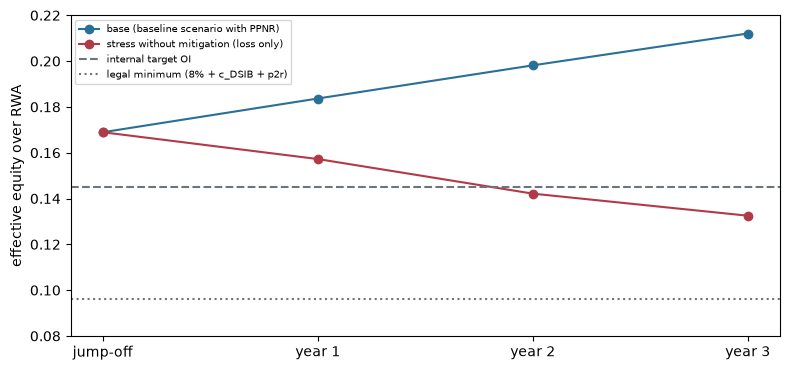

In [10]:
# Draw the effective-equity ratio of the base and the stress case against the internal target and the legal minimum
years = np.arange(0, 4)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(years, [start["pe_ratio"]] + [y.pe_pct for y in plan["base"]], marker="o", label="base (baseline scenario with PPNR)", color="#2a6f97")
ax.plot(years, [start["pe_ratio"]] + [y.pe_pct for y in plan["stress-without-mitigation"]], marker="o", label="stress without mitigation (loss only)", color="#b23a48")
ax.axhline(oi.oi, color="#6c757d", linestyle="--", label="internal target OI")
ax.axhline(legal_minimum, color="#6c757d", linestyle=":", label="legal minimum (8% + c_DSIB + p2r)")
ax.set_xticks(years)
ax.set_xticklabels(["jump-off"] + [f"year {k}" for k in (1, 2, 3)])
ax.set_ylabel("effective equity over RWA")
ax.set_ylim(0.08, 0.22)
ax.legend(fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()

- **The loss-only CET1 path falls from 11.00 to 9.83, 8.32 and 7.36 percent of RWA** (CLP 736,508, 623,333 and 551,141 million) after stressed losses of 87,706, 113,174 and 72,193 million; the engine path equals the committed one to the digit.
- **The labelled PPNR row adds about CLP 147,000 million a year** (147,813, 147,070 and 147,070) and lifts the CET1 ratio to 11.80, 12.25 and 13.25 percent, which is why the headline is the loss-only path and the row is labelled: the revenue rests on two stated ratios and on a rate path, and is not a prediction.
- **The internal target is 14.5 percent** (8 + 1.5 + 1.0 + 2.5 + 0.5 + 1.0), the article 66 quinquies requirement is 0.125 percent, the legal minimum is 9.625 percent and the CET1 stack of the reverse stress is 9.0625 percent. The engine refuses a requirement of 5 percent (cap 4) and an own estimate of 1 percent below a requirement of 2.
- **The stressed bank holds the legal minimum and misses its own target.** Without mitigation the effective-equity ratio is 15.72, 14.21 and 13.25 percent: headroom over the legal minimum of 6.10, 4.59 and 3.62 points and no deficit, but +1.22, -0.29 and -1.25 points against the 14.5 percent internal target. The base case stays 3.9 to 6.7 points above it. The mitigation case equals the unmitigated one because no action is assumed.
- **The static rule is applied as written.** New stage 3 exposure of CLP 1,131,441 million over twelve quarters moves stage 3 from 141,229 to 1,272,670 million while the total stays constant, and the engine's test is green with 12 periods, as in the committed document. With a planted cure it is red with `no-cure`; with a changed total, red with `constant-total`.
- **The P2G proxy is zero**: the largest fall of CET1/RWA, 3.64 points, is below the 4.0 points of usable buffers. It is a labelled Contraste approximation and not a requirement.
- **The 34 rows of Annex 3 rebuilt with the engine are identical to the committed rows** (row 10.1, the fall of the CET1 ratio in the stress, is 3.64 points; row 10.2 is not applicable because no mitigation is assumed; row 12, the headroom of the effective equity over the OI at the jump-off, is 2.39 points).

What this notebook does not show: the NII behind the PPNR was read, not recomputed, because it needs the interest-rate book of the case C15; the capital and RWA are anchors of a synthetic bank, so none of these ratios describes a real bank; and the stressed loss is a floor, because market and operational risk carry only their expected loss in every scenario.

## Summary

- The headline CET1 path is the starting CET1 less the cumulated stressed losses, with no revenue invented; the PPNR is a labelled row on two stated ratios.
- The internal target OI adds the 8 percent minimum, the buffers, the bank's own Pillar 2 estimate and a voluntary buffer; the 4 percent cap binds the article 66 quinquies requirement, never the own estimate, and the engine refuses both mistakes.
- `capital_plan` runs base, stress and stress with mitigation on a static balance sheet; in the severely adverse scenario the legal minimum holds in every year and the internal target does not.
- The EBA static balance-sheet rules (constant total, nothing leaves stage 3) are applied by `eba_static_balance_sheet` and checked by a test that names a planted cure and a changed total.
- The P2G figure is a labelled Contraste approximation, and the 34 rows of Annex 3 rebuilt with the engine are identical to the committed ones.

**What to try next.** Change `c_d`, the voluntary buffer, to zero in step 3 and see how the internal target and its headroom move; then continue with notebook 06, which asks the reverse question: which scenario would take the bank to the legal minimum.

## References

- EBA (2025), 2025 EU-wide stress test, Methodological Note of 2025-01-20: the static balance sheet (paragraphs 24, 33, 34 and 90 to 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- CMF Chile (2025), Circular 2.365 and Annex 3 of the IAPE capital self-assessment, the 34-row summary form. https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- Dossier 03 of the persisted Contraste research (the Chilean capital stack in 2026, the internal capital target and the stress testing inside the IAPE), as summarised in the SDD's research basis.
- This repository: `docs/contracts/engine/stress-api.md` (the capital engine) and `docs/design/features/c18/design.md`.